# RAG для психологии отношений

Выполнила: Чиркова Анна, MFAI-01

In [2]:
from pathlib import Path

data_dir = Path("data_txt")

documents = []

for file_path in sorted(data_dir.glob("doc_*.txt")):
    documents.append({
        "document_id": file_path.stem,
        "text": file_path.read_text(encoding="utf-8")
    })

print("Количество документов:", len(documents))
print("Документы:", [doc["document_id"] for doc in documents])

Количество документов: 10
Документы: ['doc_01', 'doc_02', 'doc_03', 'doc_04', 'doc_05', 'doc_06', 'doc_07', 'doc_08', 'doc_09', 'doc_10']


In [3]:
# описание корпуса

print("Корпус состоит из 10 русскоязычных текстов о близких отношениях.")
sum_words = 0
len_of_docs = []
for document in documents:
    print(document["document_id"])
    print("Количество символов: ", len(document["text"]))
    print("Количество слов: ", len(document["text"].split()))
    sum_words += len(document["text"].split())
    len_of_docs.append(len(document["text"].split()))

print("Среднее кол-во слов в документе: ", sum_words / len(documents))
print("Максимальный документ по словам - это ", len_of_docs.index(max(len_of_docs)) + 1, end='.\n')
print("Его длина = ", max(len_of_docs), end='.\n')
print("Минимальный документ по словам - это ", len_of_docs.index(min(len_of_docs)) + 1, end='.\n')
print("Его длина = ", min(len_of_docs), end='.\n')

print("Размеры документов заметно различаются, поэтому длинные документы дадут значительно больше chunks.")

Корпус состоит из 10 русскоязычных текстов о близких отношениях.
doc_01
Количество символов:  34389
Количество слов:  4703
doc_02
Количество символов:  15266
Количество слов:  1943
doc_03
Количество символов:  25528
Количество слов:  3174
doc_04
Количество символов:  31554
Количество слов:  3846
doc_05
Количество символов:  21285
Количество слов:  2716
doc_06
Количество символов:  25720
Количество слов:  3078
doc_07
Количество символов:  31407
Количество слов:  4099
doc_08
Количество символов:  55223
Количество слов:  7752
doc_09
Количество символов:  2824
Количество слов:  355
doc_10
Количество символов:  5018
Количество слов:  632
Среднее кол-во слов в документе:  3229.8
Максимальный документ по словам - это  8.
Его длина =  7752.
Минимальный документ по словам - это  9.
Его длина =  355.
Размеры документов заметно различаются, поэтому длинные документы дадут значительно больше chunks.


Для построения embeddings была выбрана многоязычная модель `intfloat/multilingual-e5-small`, поскольку корпус и запросы представлены на русском языке. У E5 текст документа должен начинаться с `passage:`, а вопрос — с `query:`. Так модель понимает роль каждого текста при поиске.

In [4]:
from transformers import AutoTokenizer

model_name = "intfloat/multilingual-e5-small"
tokenizer = AutoTokenizer.from_pretrained(model_name)

doc_01_text_info, doc_01_text = documents[0]["text"].split("\n\n", 1)
tokenized_doc_01 = tokenizer.encode(doc_01_text, add_special_tokens=False)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (8104 > 512). Running this sequence through the model will result in indexing errors


In [5]:
print("Слов:", len(doc_01_text.split()))
print("Токенов:", len(tokenized_doc_01))
print("Первые токены:", tokenized_doc_01[:20])
print("Обратно в текст:", tokenizer.decode(tokenized_doc_01[:20]))

Слов: 4673
Токенов: 8104
Первые токены: [417, 83836, 150236, 33907, 4, 414, 11285, 23520, 3997, 114872, 9395, 29, 27319, 17260, 201615, 312, 25514, 8808, 188927, 122576]
Обратно в текст: Введение Хорошо известно, что именно молодая семья является наименее устойчивой среди всех остальных типов


Я отделила служебную информацию о файле от основного текста. В поиск дальше идёт только сама статья.

## Гипотеза №1. Помогает ли overlap на границах chunks

Сначала сравню chunks по 200 токенов без пересечения и с overlap 40 токенов, то есть 20%. Проблема фиксированного деления в том, что нужная мысль может оказаться ровно между двумя кусками.

In [6]:
def fixed_size_chunking(document_id, token_ids, chunk_size=200, overlap=0):
    chunks = []
    chunk_id = 0

    if overlap < 0 or overlap >= chunk_size:
        raise ValueError("overlap должен быть от 0 до chunk_size - 1")

    for start in range(0, len(token_ids), chunk_size - overlap):
        end = min(start + chunk_size, len(token_ids))
        chunk_token_ids = token_ids[start:end]
        chunk_text = tokenizer.decode(chunk_token_ids)

        chunks.append({
            "chunk_id": f"{document_id}_chunk_{chunk_id}",
            "document_id": document_id,
            "start_token": start,
            "end_token": end,
            "token_count": len(chunk_token_ids),
            "text": chunk_text
        })
        chunk_id += 1
        if end == len(token_ids):
            break

    return chunks

In [7]:
chunks_doc_01 = fixed_size_chunking("doc_01", tokenized_doc_01)

print("Количество chunks:", len(chunks_doc_01))
print("Первый chunk:", chunks_doc_01[0])
print("Последний chunk:", chunks_doc_01[-1])

Количество chunks: 41
Первый chunk: {'chunk_id': 'doc_01_chunk_0', 'document_id': 'doc_01', 'start_token': 0, 'end_token': 200, 'token_count': 200, 'text': 'Введение Хорошо известно, что именно молодая семья является наименее устойчивой среди всех остальных типов семьи, так как ее составляют молодые, неопытные в плане жизненного и семейного опыта люди, а доступность процедуры развода при отсутствии устойчивой семейной культуры в обществе, испытывающей кризис, усугубляет ситуацию. В итого, молодая семья в России является основным фактором кризисных показателей в функционировании института семьи в России. Самый высокий процент разводов в российском обществе, согласно имеющимся данным, приходится на молодые семьи (Бричкалевич И.В., 2023), и Ростовская область не является исключением (Кириллов Д.А., 2024). По мнению экспертов, в ближайших 15 лет демографическая ситуация в изучаемом нами регионе станет еще более неблагополучной ввиду убыли населения, в структуре которого высокая доля людей 

### Теперь делаю то же самое для всего корпуса

In [8]:
all_chunks_no_overlap = []
all_chunks_with_overlap = []

for document in documents:
    document_id = document["document_id"]
    doc_text_info, doc_text = document["text"].split("\n\n", 1)
    tokenized_doc = tokenizer.encode(doc_text, add_special_tokens=False)

    chunks_no_overlap = fixed_size_chunking(document_id, tokenized_doc)
    chunks_with_overlap = fixed_size_chunking(document_id, tokenized_doc, overlap=40)

    all_chunks_no_overlap.extend(chunks_no_overlap)
    all_chunks_with_overlap.extend(chunks_with_overlap)

In [9]:
print("Без overlap:", len(all_chunks_no_overlap))
print("С overlap:", len(all_chunks_with_overlap))

print("Первые ID без overlap:",
      [chunk["chunk_id"] for chunk in all_chunks_no_overlap[:3]])

print("Первые позиции с overlap:",
      [chunk["start_token"] for chunk in all_chunks_with_overlap[:3]])

Без overlap: 300
С overlap: 369
Первые ID без overlap: ['doc_01_chunk_0', 'doc_01_chunk_1', 'doc_01_chunk_2']
Первые позиции с overlap: [0, 160, 320]


In [10]:
#ищем неустойчивые границы

doc_01_chunks = [
    chunk
    for chunk in all_chunks_no_overlap
    if chunk["document_id"] == "doc_01"
]

print(doc_01_chunks[12]["text"][-300:])
print("\n---------- ГРАНИЦА ----------\n")
print(doc_01_chunks[13]["text"][:300])
#Какие две взаимосвязанные проблемы могут выступать источниками конфликтов в молодой семье?
#Финансовые проблемы и зависимость от родителей, выражающаяся в финансовой и моральной поддержке.


ии с точки зрения поля конфликтов. Экспертные суждения показали, что имеют место быть для молодой семьи финансовые проблемы как источник конфликтов, что подтверждается многочисленными другими исследованиями (Бегинина, И. А., 2022, 6; Кикоть А. С., 2018, 10), а с этими проблемами тесна связана другая

---------- ГРАНИЦА ----------

- зависимость от родителей. Проявляется она не только в финансовой поддержке, но и моральной. Последняя выражается во влиянии на выстраивание отношений между молодыми супругами. Приведем некоторые из мнений экспертов: «...пока они только начинают работать, у них нет собственного заработка, они сильн


### Вопросы, ответы на которые находятся около границ

10 вопросов и ответов:

doc_01, граница 12 → 13
Вопрос: Какие взаимосвязанные проблемы могут быть источниками конфликтов в молодой семье?
Ответ: финансовые проблемы и зависимость от родителей — финансовая и моральная.
Особенность: overlap 40 может не захватить слова «финансовые проблемы» из-за длинной ссылки перед границей. Это хороший кандидат на случай, где overlap не поможет.

doc_02, граница 16 → 17
Вопрос: Что следует делать с дисфункциональными способами регулирования семейных конфликтов и почему?
Ответ: их невозможно полностью устранить, но нужно минимизировать, потому что они усугубляют конфликт и не приводят к его положительному разрешению.

doc_03, граница 27 → 28
Вопрос: Как качество привязанности связано с формированием защитных механизмов?
Ответ: надёжная привязанность связана с более высоким уровнем зрелых и более низким уровнем незрелых защитных механизмов; от качества привязанности зависит, какие механизмы развиваются.

doc_04, граница 32 → 33
Вопрос: Какие стили привязанности связаны с негативной моделью себя и как это проявляется при ревности?
Ответ: озабоченный и опасливый стили; нехватка уверенности связана с негативным выражением эмоций, дистанцированием и контролирующим поведением.

doc_05, граница 3 → 4
Вопрос: Что такое партнёрский фаббинг и как он может влиять на отношения?
Ответ: использование или проверка телефона рядом с партнёром; такое отвлечение может снижать удовлетворённость отношениями.

doc_06, граница 16 → 17
Вопрос: Из каких двух компонентов состоят аутентичные отношения в концепции Лопес и Райса?
Ответ: неприемлемость лжи и обмана и принятие рисков близости — готовность к открытому общению и раскрытию себя.

doc_07, граница 15 → 16
Вопрос: Как стратегии компромисса и конфронтации связаны с продолжительностью и сохранением брака?
Ответ: компромисс связан с разрешением разногласий и сохранением брака, а конфронтация обратно связана с количеством лет в браке и повышает вероятность разрыва.

doc_08, граница 49 → 50
Вопрос: Как различаются мнения мужчин и женщин поколения Z о контроле школьной успеваемости детей?
Ответ: 24% мужчин и 7,7% женщин считают это женской обязанностью; совместное выполнение выбрали 60% мужчин и 86,5% женщин.

doc_09, граница 1 → 2
Вопрос: Какую обратную связь даёт пересказ при активном слушании?
Ответ: собеседник понимает, правильно ли его услышали, и получает возможность скорректировать сказанное; пересказ также помогает подводить итоги.

doc_10, граница 3 → 4
Вопрос: Как Я-высказывание помогает регулировать эмоциональное состояние и общение?
Ответ: эмоциональная реакция переводится в рациональную словесную форму, что позволяет говорить увереннее, доброжелательнее и менее обидно для партнёра.

In [11]:
questions = [
    {
        "question_id": "q1",
        "question": "Какие взаимосвязанные проблемы могут быть источниками конфликтов в молодой семье?",
        "gold_answer": (
            "Финансовые проблемы и зависимость от родителей, "
            "которая может выражаться в финансовой и моральной поддержке."
        ),
        "document_id": "doc_01",
        "relevant_no_overlap": [
            "doc_01_chunk_12",
            "doc_01_chunk_13"
        ],
        "relevant_with_overlap": [
            "doc_01_chunk_15",
            "doc_01_chunk_16"
        ]
    },
    {
        "question_id": "q2",
        "question": (
            "Что следует делать с дисфункциональными способами "
            "регулирования семейных конфликтов и почему?"
        ),
        "gold_answer": (
            "Полностью избавиться от них невозможно, но их необходимо "
            "минимизировать, поскольку они не приводят к положительному "
            "разрешению конфликта и способствуют его усугублению."
        ),
        "document_id": "doc_02",
        "relevant_no_overlap": [
            "doc_02_chunk_16",
            "doc_02_chunk_17"
        ],
        "relevant_with_overlap": [
            "doc_02_chunk_21"
        ]
    },
    {
        "question_id": "q3",
        "question": (
            "Как качество привязанности связано с формированием "
            "защитных механизмов?"
        ),
        "gold_answer": (
            "Надёжная привязанность связана с более высоким уровнем "
            "зрелых и более низким уровнем незрелых защитных механизмов. "
            "От качества привязанности зависит, какие защитные механизмы развиваются."
        ),
        "document_id": "doc_03",
        "relevant_no_overlap": [
            "doc_03_chunk_27",
            "doc_03_chunk_28"
        ],
        "relevant_with_overlap": [
            "doc_03_chunk_34"
        ]
    },
    {
        "question_id": "q4",
        "question": (
            "Какие стили привязанности связаны с негативной моделью себя "
            "и как это проявляется при ревности?"
        ),
        "gold_answer": (
            "Озабоченный и опасливый стили привязанности связаны с "
            "негативной моделью себя. Нехватка уверенности проявляется "
            "в негативном выражении эмоций, активном дистанцировании "
            "и контролирующем поведении."
        ),
        "document_id": "doc_04",
        "relevant_no_overlap": [
            "doc_04_chunk_32",
            "doc_04_chunk_33"
        ],
        "relevant_with_overlap": [
            "doc_04_chunk_41"
        ]
    },
    {
        "question_id": "q5",
        "question": (
            "Что такое партнёрский фаббинг и как он может влиять "
            "на отношения?"
        ),
        "gold_answer": (
            "Партнёрский фаббинг — это использование мобильного телефона "
            "или отвлечение на него в присутствии романтического партнёра. "
            "Он может снижать удовлетворённость отношениями."
        ),
        "document_id": "doc_05",
        "relevant_no_overlap": [
            "doc_05_chunk_3",
            "doc_05_chunk_4"
        ],
        "relevant_with_overlap": [
            "doc_05_chunk_4"
        ]
    },
    {
        "question_id": "q6",
        "question": (
            "Из каких двух компонентов состоят аутентичные отношения "
            "в концепции Лопес и Райса?"
        ),
        "gold_answer": (
            "Первый компонент — неприемлемость лжи и обмана. "
            "Второй — принятие рисков близости, то есть готовность "
            "к открытому общению и раскрытию себя перед партнёром."
        ),
        "document_id": "doc_06",
        "relevant_no_overlap": [
            "doc_06_chunk_16",
            "doc_06_chunk_17"
        ],
        "relevant_with_overlap": [
            "doc_06_chunk_21"
        ]
    },
    {
        "question_id": "q7",
        "question": (
            "Как стратегии компромисса и конфронтации связаны "
            "с продолжительностью и сохранением брака?"
        ),
        "gold_answer": (
            "Компромисс связан с разрешением разногласий и сохранением "
            "брачных отношений. Конфронтация обратно связана с количеством "
            "лет в браке и с большей вероятностью приводит к разрыву отношений."
        ),
        "document_id": "doc_07",
        "relevant_no_overlap": [
            "doc_07_chunk_15",
            "doc_07_chunk_16"
        ],
        "relevant_with_overlap": [
            "doc_07_chunk_19"
        ]
    },
    {
        "question_id": "q8",
        "question": (
            "Как различаются мнения мужчин и женщин поколения Z "
            "о контроле школьной успеваемости детей?"
        ),
        "gold_answer": (
            "24% мужчин и 7,7% женщин считают контроль школьной "
            "успеваемости женской обязанностью. Совместное выполнение "
            "этой обязанности выбрали 60% мужчин и 86,5% женщин."
        ),
        "document_id": "doc_08",
        "relevant_no_overlap": [
            "doc_08_chunk_49",
            "doc_08_chunk_50"
        ],
        "relevant_with_overlap": [
            "doc_08_chunk_62"
        ]
    },
    {
        "question_id": "q9",
        "question": (
            "Какую обратную связь даёт пересказ при активном слушании?"
        ),
        "gold_answer": (
            "Пересказ позволяет собеседнику понять, правильно ли он был "
            "услышан, и при необходимости скорректировать свои слова. "
            "Он также может использоваться для подведения итогов."
        ),
        "document_id": "doc_09",
        "relevant_no_overlap": [
            "doc_09_chunk_1",
            "doc_09_chunk_2"
        ],
        "relevant_with_overlap": [
            "doc_09_chunk_2"
        ]
    },
    {
        "question_id": "q10",
        "question": (
            "Как Я-высказывание помогает регулировать эмоциональное "
            "состояние и общение?"
        ),
        "gold_answer": (
            "Эмоциональная реакция переводится в рациональную и словесную "
            "форму. Это помогает говорить увереннее и доброжелательнее, "
            "а негативные чувства выражать менее обидно для собеседника."
        ),
        "document_id": "doc_10",
        "relevant_no_overlap": [
            "doc_10_chunk_3",
            "doc_10_chunk_4"
        ],
        "relevant_with_overlap": [
            "doc_10_chunk_4"
        ]
    }
]

In [12]:
print("Количество вопросов:", len(questions))

for item in questions:
    print(
        item["question_id"],
        item["document_id"],
        item["question"]
    )

Количество вопросов: 10
q1 doc_01 Какие взаимосвязанные проблемы могут быть источниками конфликтов в молодой семье?
q2 doc_02 Что следует делать с дисфункциональными способами регулирования семейных конфликтов и почему?
q3 doc_03 Как качество привязанности связано с формированием защитных механизмов?
q4 doc_04 Какие стили привязанности связаны с негативной моделью себя и как это проявляется при ревности?
q5 doc_05 Что такое партнёрский фаббинг и как он может влиять на отношения?
q6 doc_06 Из каких двух компонентов состоят аутентичные отношения в концепции Лопес и Райса?
q7 doc_07 Как стратегии компромисса и конфронтации связаны с продолжительностью и сохранением брака?
q8 doc_08 Как различаются мнения мужчин и женщин поколения Z о контроле школьной успеваемости детей?
q9 doc_09 Какую обратную связь даёт пересказ при активном слушании?
q10 doc_10 Как Я-высказывание помогает регулировать эмоциональное состояние и общение?


In [13]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(model_name)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4369.34it/s]


In [14]:
texts_no_overlap = [
    "passage: " + chunk["text"]
    for chunk in all_chunks_no_overlap
]

embeddings_no_overlap = embedding_model.encode(
    texts_no_overlap,
    normalize_embeddings=True,
    batch_size=64,
    show_progress_bar=False
)

texts_with_overlap = [
    "passage: " + chunk["text"]
    for chunk in all_chunks_with_overlap
]

embeddings_with_overlap = embedding_model.encode(
    texts_with_overlap,
    normalize_embeddings=True,
    batch_size=64,
    show_progress_bar=False
)

print("Форма embeddings без overlap:", embeddings_no_overlap.shape)
print("Форма embeddings с overlap:", embeddings_with_overlap.shape)

Форма embeddings без overlap: (300, 384)
Форма embeddings с overlap: (369, 384)


## Векторные коллекции и проверка Recall@k

Для каждого варианта создаю отдельную коллекцию Chroma. Метрика, которвя нам нужна считается так: какая доля подходящих chunks попала в первые `k` результатов (я их размечала сама и это 1 или 2 chunk'a).

In [ ]:
import chromadb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

chroma_client = chromadb.EphemeralClient()

collection_no_overlap = chroma_client.get_or_create_collection(
    name="fixed_no_overlap",
    configuration={"hnsw": {"space": "cosine"}}
)
collection_with_overlap = chroma_client.get_or_create_collection(
    name="fixed_with_overlap",
    configuration={"hnsw": {"space": "cosine"}}
)

# нам надо записать коллекции для того, чтобы мы могли среди них искать наиболее подходящие эмбеддинги
def fill_collection(collection, chunks, embeddings):
    collection.upsert(
        ids=[chunk["chunk_id"] for chunk in chunks],
        embeddings=embeddings.tolist(),
        documents=[chunk["text"] for chunk in chunks],
        metadatas=[{"document_id": chunk["document_id"]} for chunk in chunks]
    )

fill_collection(collection_no_overlap, all_chunks_no_overlap, embeddings_no_overlap)
fill_collection(collection_with_overlap, all_chunks_with_overlap, embeddings_with_overlap)

print("Объектов без overlap:", collection_no_overlap.count())
print("Объектов с overlap:", collection_with_overlap.count())

Объектов без overlap: 300
Объектов с overlap: 369


In [ ]:
def query_embedding(question):
    return embedding_model.encode(
        ["query: " + question],
        normalize_embeddings=True,
        show_progress_bar=False
    )[0]

def search_chroma(collection, question, k=5):
    result = collection.query(
        query_embeddings=[query_embedding(question).tolist()],
        n_results=min(k, collection.count())
    )
    return result["ids"][0]

def recall_at_k(retrieved_ids, relevant_ids):
    relevant = set(relevant_ids)
    if not relevant:
        return 0.0
    return len(set(retrieved_ids) & relevant) / len(relevant) 

def evaluate_collection(collection, question_list, relevant_field, ks=(1, 3, 5)):
    rows = []
    for item in question_list:
        row = {"question_id": item["question_id"]}
        for k in ks:
            retrieved = search_chroma(collection, item["question"], k=k)
            row[f"recall@{k}"] = recall_at_k(retrieved, item[relevant_field])
        rows.append(row)
    return pd.DataFrame(rows)

results_no_overlap = evaluate_collection(
    collection_no_overlap, questions, "relevant_no_overlap"
)
results_with_overlap = evaluate_collection(
    collection_with_overlap, questions, "relevant_with_overlap"
)

comparison_h1 = results_no_overlap.merge(
    results_with_overlap,
    on="question_id",
    suffixes=("_no_overlap", "_with_overlap")
)
comparison_h1

,question_id,recall@1_no_overlap,recall@3_no_overlap,recall@5_no_overlap,recall@1_with_overlap,recall@3_with_overlap,recall@5_with_overlap
0,q1,0.5,0.5,0.5,0.0,0.5,0.5
1,q2,0.0,0.5,0.5,0.0,0.0,1.0
2,q3,0.5,1.0,1.0,0.0,0.0,1.0
3,q4,0.0,0.0,0.5,0.0,0.0,0.0
4,q5,0.5,0.5,1.0,0.0,1.0,1.0
5,q6,0.5,1.0,1.0,1.0,1.0,1.0
6,q7,0.0,0.0,0.0,0.0,0.0,0.0
7,q8,0.5,0.5,0.5,1.0,1.0,1.0
8,q9,0.0,1.0,1.0,0.0,1.0,1.0
9,q10,0.0,1.0,1.0,0.0,1.0,1.0


,recall@1,recall@3,recall@5
без overlap,0.25,0.60,0.70
с overlap,0.20,0.55,0.75


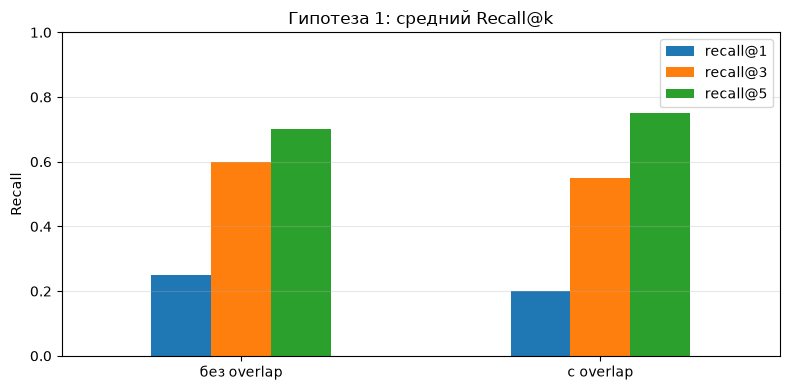

In [17]:
h1_means = pd.DataFrame({
    "без overlap": results_no_overlap[["recall@1", "recall@3", "recall@5"]].mean(),
    "с overlap": results_with_overlap[["recall@1", "recall@3", "recall@5"]].mean()
}).T

display(h1_means.round(3))

ax = h1_means.plot(kind="bar", figsize=(8, 4), ylim=(0, 1), rot=0)
ax.set_title("Гипотеза 1: средний Recall@k")
ax.set_ylabel("Recall")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

На самом деле уже тут можно засомневаться в том, нужно ли нам тратить дополнительную память и вычислительную мощность, учитывая, что при k=1 и k=3 мы не выигрываем, а при k=5 выигрываем всего лишь на 0.05. 

In [18]:
extra_chunks = len(all_chunks_with_overlap) - len(all_chunks_no_overlap)
extra_percent = extra_chunks / len(all_chunks_no_overlap) * 100
memory_no = embeddings_no_overlap.nbytes / 1024**2
memory_overlap = embeddings_with_overlap.nbytes / 1024**2

print(f"Дополнительных chunks: {extra_chunks} ({extra_percent:.1f}%)")
print(f"Память embeddings без overlap: {memory_no:.2f} МБ")
print(f"Память embeddings с overlap: {memory_overlap:.2f} МБ")
print(f"Дополнительная память: {memory_overlap - memory_no:.2f} МБ")

comparison_h1["изменение_recall@5"] = (
    comparison_h1["recall@5_with_overlap"] - comparison_h1["recall@5_no_overlap"]
)
print("\nГде overlap помог или не помог:")
display(comparison_h1[["question_id", "изменение_recall@5"]])

print("\nДва примера поиска:")
for example_id in ["q2", "q1"]:
    item = next(question for question in questions if question["question_id"] == example_id)
    print("\n", example_id, item["question"])
    print("без overlap:", search_chroma(collection_no_overlap, item["question"], 5))
    print("с overlap:", search_chroma(collection_with_overlap, item["question"], 5))

Дополнительных chunks: 69 (23.0%)
Память embeddings без overlap: 0.44 МБ
Память embeddings с overlap: 0.54 МБ
Дополнительная память: 0.10 МБ

Где overlap помог или не помог:


,question_id,изменение_recall@5
0,q1,0.0
1,q2,0.5
2,q3,0.0
3,q4,-0.5
4,q5,0.0
5,q6,0.0
6,q7,0.0
7,q8,0.5
8,q9,0.0
9,q10,0.0



Два примера поиска:

 q2 Что следует делать с дисфункциональными способами регулирования семейных конфликтов и почему?
без overlap: ['doc_02_chunk_8', 'doc_02_chunk_7', 'doc_02_chunk_16', 'doc_02_chunk_1', 'doc_02_chunk_3']
с overlap: ['doc_02_chunk_9', 'doc_02_chunk_10', 'doc_02_chunk_20', 'doc_02_chunk_21', 'doc_02_chunk_8']

 q1 Какие взаимосвязанные проблемы могут быть источниками конфликтов в молодой семье?
без overlap: ['doc_01_chunk_12', 'doc_01_chunk_37', 'doc_01_chunk_27', 'doc_07_chunk_3', 'doc_01_chunk_6']
с overlap: ['doc_01_chunk_33', 'doc_01_chunk_15', 'doc_01_chunk_46', 'doc_01_chunk_17', 'doc_01_chunk_21']


Даже пожертвовав памятью, мы всё равно не можем быть уверены в стопроцентном результате: ответы всё ещё могут находиться на границах chunks. В нашем эксперименте overlap увеличил количество chunks с 300 до 369, то есть на 23%, а Recall@5 вырос только с 0.70 до 0.75. В некоторых случаях overlap действительно помог, например в вопросах q2 и q8, но для большинства вопросов результат не изменился, а для q4 даже стал хуже. Поэтому использование overlap зависит от конкретной задачи: нужно учитывать не только возможное улучшение поиска, но и увеличение объёма памяти и количества объектов в базе.

## Гипотеза №2. Смысловые chunks

Теперь границы зависят не от номера токена, а от связи соседних предложений. Алгоритм такой:

1. делю документ на предложения;
2. получаю embedding каждого предложения;
3. считаю cosine similarity соседних предложений;
4. беру 25-й перцентиль сходства как порог;
5. если сходство ниже порога, начинаю новый chunk.


In [19]:
from razdel import sentenize

def semantic_chunking(document_id, text, percentile=25):
    sentences = [item.text.strip() for item in sentenize(text) if item.text.strip()]

    if len(sentences) == 1:
        return [{
            "chunk_id": f"{document_id}_semantic_0",
            "document_id": document_id,
            "start_sentence": 0,
            "end_sentence": 1,
            "token_count": len(tokenizer.encode(sentences[0], add_special_tokens=False)),
            "threshold": None,
            "text": sentences[0]
        }]

    sentence_embeddings = embedding_model.encode(
        ["query: " + sentence for sentence in sentences],
        normalize_embeddings=True,
        batch_size=64,
        show_progress_bar=False
    )
    similarities = np.sum(sentence_embeddings[:-1] * sentence_embeddings[1:], axis=1)
    threshold = float(np.percentile(similarities, percentile))

    boundaries = [0]
    for index, similarity in enumerate(similarities, start=1):
        if similarity < threshold:
            boundaries.append(index)
    boundaries.append(len(sentences))

    preliminary_chunks = []
    for chunk_number, (start, end) in enumerate(zip(boundaries[:-1], boundaries[1:])):
        chunk_text = " ".join(sentences[start:end])
        preliminary_chunks.append({
            "document_id": document_id,
            "start_sentence": start,
            "end_sentence": end,
            "threshold": threshold,
            "text": chunk_text
        })

    # E5 принимает не больше 512 токенов. Очень длинные фрагменты
    # дополнительно делю на части по 450 токенов, чтобы модель их не обрезала.
    chunks = []
    for preliminary in preliminary_chunks:
        token_ids = tokenizer.encode(preliminary["text"], add_special_tokens=False)
        for start_token in range(0, len(token_ids), 450):
            part_ids = token_ids[start_token:start_token + 450]
            chunks.append({
                "chunk_id": f"{document_id}_semantic_{len(chunks)}",
                "document_id": document_id,
                "start_sentence": preliminary["start_sentence"],
                "end_sentence": preliminary["end_sentence"],
                "token_count": len(part_ids),
                "threshold": threshold,
                "text": tokenizer.decode(part_ids)
            })
    return chunks

all_semantic_chunks = []
for document in documents:
    document_id = document["document_id"]
    _, document_text = document["text"].split("\n\n", 1)
    all_semantic_chunks.extend(semantic_chunking(document_id, document_text))

semantic_sizes = np.array([chunk["token_count"] for chunk in all_semantic_chunks])
print("Количество смысловых chunks:", len(all_semantic_chunks))
print("Медианный размер:", int(np.median(semantic_sizes)), "токенов")
print("Минимум / максимум:", semantic_sizes.min(), "/", semantic_sizes.max())

Количество смысловых chunks: 420
Медианный размер: 90 токенов
Минимум / максимум: 2 / 450


In [20]:
semantic_embeddings = embedding_model.encode(
    ["passage: " + chunk["text"] for chunk in all_semantic_chunks],
    normalize_embeddings=True,
    batch_size=64,
    show_progress_bar=False
)

collection_semantic = chroma_client.get_or_create_collection(
    name="semantic_chunks",
    configuration={"hnsw": {"space": "cosine"}}
)
fill_collection(collection_semantic, all_semantic_chunks, semantic_embeddings)

semantic_anchor_terms = {
    "q1": ["финансовые проблемы", "зависимость от родителей"],
    "q2": ["минимизировать", "усугублению"],
    "q3": ["зрелых защитных механизмов", "незрелых защитных механизмов"],
    "q4": ["озабоченные и опасливые", "контролирующего поведения"],
    "q5": ["партнерский фаббинг", "мобильный телефон"],
    "q6": ["неприемлемость лжи и обмана", "принятие рисков близости"],
    "q7": ["стратегию компромисса", "стратегии конфронтация"],
    "q8": ["24% мужчин", "7,7% женщин"],
    "q9": ["скорректировать свои слова", "подведения итогов"],
    "q10": ["рациональную и вербальную форму", "менее обидной"]
}

def relevant_semantic_ids(question_item):
    anchors = semantic_anchor_terms[question_item["question_id"]]
    document_id = question_item["document_id"]
    result = []
    for chunk in all_semantic_chunks:
        if chunk["document_id"] != document_id:
            continue
        lower_text = chunk["text"].lower().replace("ё", "е")
        if any(anchor.lower().replace("ё", "е") in lower_text for anchor in anchors):
            result.append(chunk["chunk_id"])
    return result

questions_semantic = []
for item in questions:
    item_copy = item.copy()
    item_copy["relevant_semantic"] = relevant_semantic_ids(item)
    questions_semantic.append(item_copy)

print("Число отмеченных смысловых chunks для каждого вопроса:")
print({item["question_id"]: len(item["relevant_semantic"]) for item in questions_semantic})

Число отмеченных смысловых chunks для каждого вопроса:
{'q1': 3, 'q2': 1, 'q3': 1, 'q4': 3, 'q5': 3, 'q6': 1, 'q7': 4, 'q8': 1, 'q9': 1, 'q10': 1}


,recall@1,recall@3,recall@5
fixed без overlap,0.250,0.600,0.700
fixed с overlap,0.200,0.550,0.750
semantic,0.467,0.633,0.658


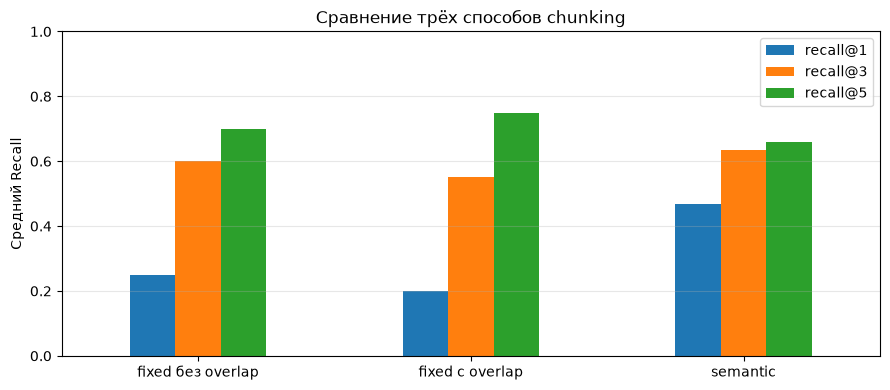

In [21]:
results_semantic = evaluate_collection(
    collection_semantic, questions_semantic, "relevant_semantic"
)

all_chunking_means = pd.DataFrame({
    "fixed без overlap": results_no_overlap[["recall@1", "recall@3", "recall@5"]].mean(),
    "fixed с overlap": results_with_overlap[["recall@1", "recall@3", "recall@5"]].mean(),
    "semantic": results_semantic[["recall@1", "recall@3", "recall@5"]].mean()
}).T

display(all_chunking_means.round(3))

ax = all_chunking_means.plot(kind="bar", figsize=(9, 4), ylim=(0, 1), rot=0)
ax.set_title("Сравнение трёх способов chunking")
ax.set_ylabel("Средний Recall")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Мы видим сильное улучшение при маленьком значении k, особенно при k=1: Recall вырос до 0.467, тогда как у fixed-size вариантов он составлял 0.250 и 0.200. Получается, что смысловое разделение помогает точнее находить подходящий фрагмент среди первых результатов. Однако при k=5 semantic chunking показывает результат 0.658 и уступает fixed-size chunking. То есть этот способ улучшает точность первого найденного фрагмента, но не всегда обеспечивает лучшую полноту поиска.

In [22]:
def show_semantic_example(document_id, number=0):
    choices = [chunk for chunk in all_semantic_chunks if chunk["document_id"] == document_id]
    chunk = choices[number]
    print(chunk["chunk_id"], "|", chunk["token_count"], "токенов")
    print(chunk["text"][:1200])

print("Пример смыслового chunk:")
show_semantic_example("doc_05", 1)

print("\nСмысловой chunk с ответом на q2:")
q2_semantic_ids = next(
    item["relevant_semantic"] for item in questions_semantic if item["question_id"] == "q2"
)
for chunk_id in q2_semantic_ids:
    chunk = next(chunk for chunk in all_semantic_chunks if chunk["chunk_id"] == chunk_id)
    print(chunk_id, "->", chunk["text"][:800])

Пример смыслового chunk:
doc_05_semantic_1 | 16 токенов
28,4% мужчин и 71,6% женщин, средний возраст 21,9 года).

Смысловой chunk с ответом на q2:
doc_02_semantic_27 -> Однако необходима и возможна их минимизация, поскольку они не влекут за собой позитивного разрешения конфликта, способствуют его усугублению.


У смыслового деления chunks получаются разной длины. Это ожидаемо: одна мысль может занимать одно короткое предложение, а другая — целый абзац. Поэтому здесь я смотрю не только на recall, но и на максимальный размер. Слишком длинный chunk может ухудшить поиск и занять лишнее место в контексте LLM.

## Гипотеза №3. Dense, BM25 и гибридный поиск

In [23]:
import re
from rank_bm25 import BM25Okapi

def bm25_tokenize(text):
    text = text.lower().replace("ё", "е")
    return re.findall(r"[a-zа-я0-9]+(?:[,.=-][0-9]+)?", text)

bm25_corpus = [bm25_tokenize(chunk["text"]) for chunk in all_chunks_with_overlap]
bm25 = BM25Okapi(bm25_corpus)

chunk_ids_overlap = [chunk["chunk_id"] for chunk in all_chunks_with_overlap]
chunk_by_id_overlap = {chunk["chunk_id"]: chunk for chunk in all_chunks_with_overlap}

def dense_ranking(question, n=20):
    query_vector = query_embedding(question)
    scores = embeddings_with_overlap @ query_vector
    order = np.argsort(scores)[::-1][:n]
    return [chunk_ids_overlap[index] for index in order]

def bm25_ranking(question, n=20):
    scores = bm25.get_scores(bm25_tokenize(question))
    order = np.argsort(scores)[::-1][:n]
    return [chunk_ids_overlap[index] for index in order]

def rrf_ranking(question, n=20, candidate_count=60, rrf_k=60):
    dense_ids = dense_ranking(question, candidate_count)
    bm25_ids = bm25_ranking(question, candidate_count)
    scores = {}
    for ranking in (dense_ids, bm25_ids):
        for rank, chunk_id in enumerate(ranking, start=1):
            scores[chunk_id] = scores.get(chunk_id, 0) + 1 / (rrf_k + rank)
    return [chunk_id for chunk_id, _ in sorted(scores.items(), key=lambda x: x[1], reverse=True)[:n]]

In [24]:
hard_questions = [
    {
        "question_id": "hard_1",
        "question": "Что измеряет шкала ACRS и какие три компонента в неё входят?",
        "gold_answer": "Осведомлённость, смелость и отзывчивость в аутентичных отношениях",
        "relevant_ids": ["doc_06_chunk_33", "doc_06_chunk_34"]
    },
    {
        "question_id": "hard_2",
        "question": "Как в статье интерпретируется связь r=0,532; p<0,02 между фаббингом мужчин и их амбивалентностью?",
        "gold_answer": "Чем сильнее противоречивость чувств мужчины, тем больше женщина ощущает фаббинг",
        "relevant_ids": ["doc_05_chunk_27"]
    },
    {
        "question_id": "hard_3",
        "question": "Что показывают коэффициенты -0,779306 и 0,613170 для конфронтации и компромисса?",
        "gold_answer": "Связь лет брака с конфронтацией отрицательная, а с компромиссом положительная",
        "relevant_ids": ["doc_07_chunk_20"]
    },
    {
        "question_id": "hard_4",
        "question": "О какой домашней обязанности говорится во фрагменте с 52% мужчин и 25% женщин поколения Z?",
        "gold_answer": "О глажении белья как женской обязанности",
        "relevant_ids": ["doc_08_chunk_61"]
    },
    {
        "question_id": "hard_5",
        "question": "Что измеряет шкала Partner phubbing (Pphubbing)?",
        "gold_answer": "Фаббинг романтического партнёра",
        "relevant_ids": ["doc_05_chunk_10"]
    }
]

normal_ids = {"q1", "q2", "q3", "q9", "q10"}
normal_questions = []
for item in questions:
    if item["question_id"] in normal_ids:
        normal_questions.append({
            "question_id": item["question_id"],
            "question": item["question"],
            "gold_answer": item["gold_answer"],
            "relevant_ids": item["relevant_with_overlap"]
        })

print("Точных вопросов:", len(hard_questions))
print("Обычных вопросов:", len(normal_questions))

Точных вопросов: 5
Обычных вопросов: 5


In [25]:
retrievers = {
    "Dense": dense_ranking,
    "BM25": bm25_ranking,
    "RRF": rrf_ranking
}

def evaluate_rankers(question_list, question_type, ks=(1, 3, 5)):
    rows = []
    for method_name, ranker in retrievers.items():
        for item in question_list:
            ranking = ranker(item["question"], max(ks))
            row = {
                "тип вопроса": question_type,
                "метод": method_name,
                "question_id": item["question_id"]
            }
            for k in ks:
                row[f"recall@{k}"] = recall_at_k(ranking[:k], item["relevant_ids"])
            rows.append(row)
    return pd.DataFrame(rows)

h3_results = pd.concat([
    evaluate_rankers(hard_questions, "точные"),
    evaluate_rankers(normal_questions, "обычные")
], ignore_index=True)

h3_summary = h3_results.groupby(["тип вопроса", "метод"])[
    ["recall@1", "recall@3", "recall@5"]
].mean().round(3)

display(h3_summary)

best_search_method_h3 = h3_results.groupby("метод")["recall@5"].mean().idxmax()
selected_ranker = retrievers[best_search_method_h3]
print("Лучший метод по среднему Recall@5:", best_search_method_h3)

recall@1  recall@3  recall@5
тип вопроса метод                              
обычные     BM25        0.5       0.5       0.5
            Dense       0.0       0.5       0.9
            RRF         0.1       0.7       0.7
точные      BM25        0.9       0.9       0.9
            Dense       0.5       0.8       0.8
            RRF         0.5       0.7       0.9

Лучший метод по среднему Recall@5: Dense


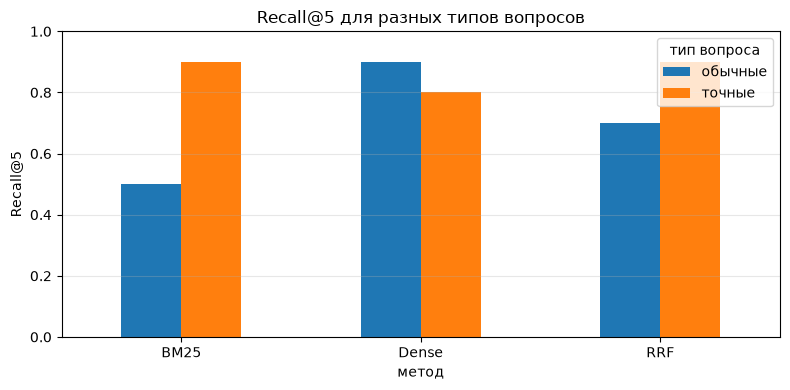

Вопрос: Как в статье интерпретируется связь r=0,532; p<0,02 между фаббингом мужчин и их амбивалентностью?
Dense -> ['doc_05_chunk_27', 'doc_05_chunk_28', 'doc_05_chunk_24']
BM25 -> ['doc_05_chunk_27', 'doc_05_chunk_24', 'doc_05_chunk_28']
RRF -> ['doc_05_chunk_27', 'doc_05_chunk_28', 'doc_05_chunk_24']


In [26]:
h3_plot = h3_summary["recall@5"].unstack(0)
ax = h3_plot.plot(kind="bar", figsize=(8, 4), ylim=(0, 1), rot=0)
ax.set_title("Recall@5 для разных типов вопросов")
ax.set_ylabel("Recall@5")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

example_question = hard_questions[1]
print("Вопрос:", example_question["question"])
for method_name, ranker in retrievers.items():
    print(method_name, "->", ranker(example_question["question"], 3))

Здесь для меня главное различие такое: BM25 ищет совпадающие формы слов и числа, dense — близкий смысл, а RRF старается не потерять сильные стороны обоих списков. По таблице можно отдельно увидеть, какой метод лучше на точных и на обычных вопросах. Один метод не обязан выигрывать во всех строках.

## Гипотеза №4. Как top-k влияет на ответ RAG

Я выбрала вариант с `top-k = 1, 3, 5, 10`. Для поиска использую метод, который оказался лучшим по среднему Recall@5 в предыдущей части, а для генерации — небольшую открытую модель `Qwen2.5-0.5B-Instruct`. Она запускается локально, поэтому результат увидим здесь и бесплатно)

Идея проверки: маленький `k` может не дать модели все факты, а большой `k` добавляет лишний текст. Во втором случае модель может начать смешивать сведения или пропускать важное в середине контекста.

In [27]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer as GeneratorTokenizer

local_generator = Path(
    ".hf_cache/hub/models--Qwen--Qwen2.5-0.5B-Instruct/"
    "snapshots/7ae557604adf67be50417f59c2c2f167def9a775"
)
generator_name = str(local_generator) if local_generator.exists() else "Qwen/Qwen2.5-0.5B-Instruct"

generator_tokenizer = GeneratorTokenizer.from_pretrained(generator_name)
generator_model = AutoModelForCausalLM.from_pretrained(
    generator_name,
    dtype=torch.float32
)
generator_model.eval()
torch.set_num_threads(min(12, torch.get_num_threads()))

print("Генеративная модель загружена:", generator_name)

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 553.22it/s]

Генеративная модель загружена: .hf_cache/hub/models--Qwen--Qwen2.5-0.5B-Instruct/snapshots/7ae557604adf67be50417f59c2c2f167def9a775


In [28]:
def generate_rag_answer(question, chunk_ids):
    context_parts = []
    for number, chunk_id in enumerate(chunk_ids, start=1):
        context_parts.append(f"[{number}] {chunk_by_id_overlap[chunk_id]['text']}")
    context = "\n\n".join(context_parts)

    messages = [
        {
            "role": "system",
            "content": (
                "Ты отвечаешь только по данному контексту. Ответь по-русски, кратко и по существу. "
                "Если факта в контексте нет, прямо скажи об этом. Не добавляй факты от себя."
            )
        },
        {
            "role": "user",
            "content": f"Контекст:\n{context}\n\nВопрос: {question}"
        }
    ]

    prompt = generator_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    model_inputs = generator_tokenizer(prompt, return_tensors="pt")
    with torch.inference_mode():
        generated = generator_model.generate(
            **model_inputs,
            max_new_tokens=60,
            do_sample=False,
            pad_token_id=generator_tokenizer.eos_token_id
        )
    answer_tokens = generated[0, model_inputs["input_ids"].shape[1]:]
    return generator_tokenizer.decode(answer_tokens, skip_special_tokens=True).strip(), context

top_k_values = [1, 3, 5, 10]
rag_rows = []

for item in questions:
    full_ranking = selected_ranker(item["question"], max(top_k_values))
    for k in top_k_values:
        answer, context = generate_rag_answer(item["question"], full_ranking[:k])
        rag_rows.append({
            "question_id": item["question_id"],
            "question": item["question"],
            "k": k,
            "answer": answer,
            "context": context
        })
    print("Готово:", item["question_id"])

rag_results = pd.DataFrame(rag_rows)
display(rag_results[["question_id", "k", "answer"]])

Готово: q1
Готово: q2
Готово: q3
Готово: q4
Готово: q5
Готово: q6
Готово: q7
Готово: q8
Готово: q9
Готово: q10


,question_id,k,answer
0,q1,1,"Существует несколько взаимосвязанных проблем, ..."
1,q1,3,"Основные взаимосвязанные проблемы, вызывающие ..."
2,q1,5,"Основные взаимосвязанные проблемы, которые мог..."
3,q1,10,"Основные взаимосвязанные проблемы, которые мог..."
4,q2,1,Дисфункциональные методы регулирования семейны...
5,q2,3,Дисфункциональные способы регулирования конфли...
6,q2,5,Дисфункциональные способы регулирования конфли...
7,q2,10,Дисфункциональные способы регулирования конфли...
8,q3,1,Качество привязанности связано с формированием...
9,q3,3,Количество надежной привязанности в детском во...


### Как оцениваю ответы

Чтобы оценка не зависела только от впечатления, для каждого вопроса я заранее выделила группы обязательных фактов. `coverage` показывает, какая доля этих групп есть в ответе. `grounding` — какая доля содержательных основ слов из ответа встречалась в переданном контексте. Это не идеальная автоматическая оценка, поэтому ниже я ещё отдельно смотрю примеры ответов.

In [29]:
answer_key_groups = {
    "q1": [["финанс"], ["родител"]],
    "q2": [["миним"], ["усугуб", "положительн"]],
    "q3": [["надежн", "надёжн"], ["зрел"], ["незрел"]],
    "q4": [["озабоч"], ["опаслив"], ["дистанц", "контрол"]],
    "q5": [["телефон"], ["партнер", "партнёр"], ["удовлетвор"]],
    "q6": [["лож", "обман"], ["риск"], ["открыт", "раскрыт"]],
    "q7": [["компромисс"], ["конфронтац"], ["разрыв", "сохран"]],
    "q8": [["24"], ["7,7"], ["60"], ["86,5"]],
    "q9": [["правильн"], ["скоррект"], ["итог"]],
    "q10": [["рациональ"], ["словес", "вербаль"], ["доброжел", "обид"]]
}

stop_words = {
    "это", "как", "что", "для", "при", "или", "она", "они", "его", "ему", "также",
    "который", "которая", "которые", "может", "быть", "более", "менее", "между", "ответ"
}

def fact_coverage(question_id, answer):
    answer_lower = answer.lower().replace("ё", "е")
    groups = answer_key_groups[question_id]
    found = sum(
        any(term.replace("ё", "е") in answer_lower for term in alternatives)
        for alternatives in groups
    )
    return found / len(groups)

def content_stems(text):
    words = bm25_tokenize(text)
    return {word[:6] for word in words if len(word) >= 4 and word not in stop_words}

def grounding_score(answer, context):
    answer_stems = content_stems(answer)
    context_stems = content_stems(context)
    if not answer_stems:
        return 0.0
    return len(answer_stems & context_stems) / len(answer_stems)

rag_results["coverage"] = rag_results.apply(
    lambda row: fact_coverage(row["question_id"], row["answer"]), axis=1
)
rag_results["grounding"] = rag_results.apply(
    lambda row: grounding_score(row["answer"], row["context"]), axis=1
)
rag_results["quality_1_to_5"] = np.clip(
    np.rint(1 + 3 * rag_results["coverage"] + rag_results["grounding"]),
    1, 5
).astype(int)
rag_results["низкая_опора_на_контекст"] = rag_results["grounding"] < 0.55

top_k_summary = rag_results.groupby("k").agg(
    средняя_оценка=("quality_1_to_5", "mean"),
    полнота_фактов=("coverage", "mean"),
    опора_на_контекст=("grounding", "mean"),
    доля_рисковых_ответов=("низкая_опора_на_контекст", "mean")
).round(3)

display(top_k_summary)

,средняя_оценка,полнота_фактов,опора_на_контекст,доля_рисковых_ответов
k,,,,
1,2.4,0.267,0.590,0.5
3,2.8,0.317,0.727,0.2
5,3.4,0.483,0.785,0.0
10,3.0,0.383,0.809,0.1


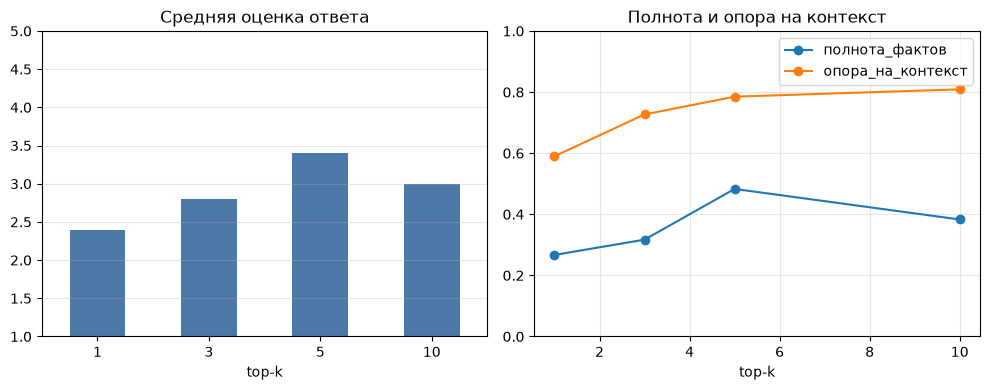

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

top_k_summary["средняя_оценка"].plot(
    kind="bar", ax=axes[0], color="#4C78A8", ylim=(1, 5), rot=0
)
axes[0].set_title("Средняя оценка ответа")
axes[0].set_xlabel("top-k")
axes[0].grid(axis="y", alpha=0.3)

top_k_summary[["полнота_фактов", "опора_на_контекст"]].plot(
    marker="o", ax=axes[1], ylim=(0, 1)
)
axes[1].set_title("Полнота и опора на контекст")
axes[1].set_xlabel("top-k")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
print("Один и тот же вопрос при разных top-k:\n")
example_k = rag_results[rag_results["question_id"] == "q8"]
for _, row in example_k.iterrows():
    print(f"top-k={row['k']} | оценка={row['quality_1_to_5']}")
    print(row["answer"])
    print("-" * 80)

Один и тот же вопрос при разных top-k:

top-k=1 | оценка=2
Мужчины и женщины поколения Z различаются в отношении того, как они оценивают роль женщин в управлении воспитанием детей. Мужчины полагают, что женщины должны контролировать детей, а женщины считают
--------------------------------------------------------------------------------
top-k=3 | оценка=2
Мужчины поколения Z полагают, что контролировать детей-школьников должен женщина, тогда как женщины думают, что это должно быть сделано мужчинами.
--------------------------------------------------------------------------------
top-k=5 | оценка=2
Мужчины и женщины поколения Z варьируют свои мнения о контроле успеваемости детей. Мужчины полагают, что контролировать детей-школьников должен женщина, тогда как женщины считают, что это также должна
--------------------------------------------------------------------------------
top-k=10 | оценка=2
Мужчины поколения Z полагают, что контролировать детей-школьников должна женщина, тогда как ж

## Общий вывод

В этой работе я проверила всю цепочку RAG: деление текста, поиск и объём контекста для генерации.

В первой гипотезе overlap 40 токенов немного поднял Recall@5: с 0.70 до 0.75. Но число chunks выросло с 300 до 369, то есть на 23%. Получилось, что overlap полезен не для каждого вопроса: он помог на q2 и q8, на большинстве вопросов ничего не изменил, а на q4 результат стал хуже.

Смысловое деление дало лучший Recall@1 — 0.467, но при `k=5` уступило fixed chunking. После дополнительного ограничения все смысловые chunks помещаются в лимит E5: максимальный размер равен 450 токенам. Значит, смысловая граница сама по себе ещё не гарантирует лучший поиск, а размер chunk всё равно надо контролировать.

В третьей гипотезе BM25 лучше всего показал себя на точных запросах: Recall@5 = 0.90. Dense оказался сильнее на обычных вопросах: Recall@5 = 0.90. По среднему результату двух групп победил Dense (0.85), затем RRF (0.80) и BM25 (0.70). Гибрид здесь не превзошёл dense, потому что ошибки BM25 иногда поднимали нерелевантные chunks.

В последнем эксперименте лучший результат получился при `top-k=5`: средняя оценка 3.4 из 5. При `k=10` опора на контекст выросла, но полнота ключевых фактов и общая оценка снизились. Это похоже на эффект лишнего контекста: модель видит больше текста, но не обязательно лучше выделяет нужный факт. На вопросе q8 модель так и не назвала проценты, хотя нужный chunk был найден. Поэтому качество RAG зависит не только от retrieval, но и от возможностей самой генеративной модели.


In [32]:
best_h1 = h1_means["recall@5"].idxmax()
best_h3 = h3_results.groupby("метод")["recall@5"].mean().idxmax()
best_k = top_k_summary["средняя_оценка"].idxmax()

print("Лучший вариант в гипотезе 1 по Recall@5:", best_h1)
print("Лучший способ поиска по среднему Recall@5:", best_h3)
print("Лучший top-k по средней оценке:", best_k)

Лучший вариант в гипотезе 1 по Recall@5: с overlap
Лучший способ поиска по среднему Recall@5: Dense
Лучший top-k по средней оценке: 5
